In [31]:
from src.evaluation import (
    find_best_threshold,
    evaluate_predictions,
    build_model_comparison,
    calculate_runtime_metrics
)

print("Evaluation module connected successfully!")

Evaluation module connected successfully!


In [16]:

# Add project root to Python path

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "src" / "models.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root not found!")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Models file found:",
      (PROJECT_ROOT / "src" / "models.py").exists())


Project root: C:\Users\Nalindu\Desktop\ML
Models file found: True


In [17]:
from src.models import calculate_anomaly_scores

print("K-Means functions imported successfully!")

K-Means functions imported successfully!


In [11]:

# ==========================================
# MEMBER 04 - MODEL EVALUATION
# STEP 1: DATA LOADING AND ALIGNMENT
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# ------------------------------------------
# 1. Locate project directory
# ------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data" / "processed").exists():
    raise FileNotFoundError(
        "Processed data folder not found!"
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DIR = PROJECT_ROOT / "data" / "raw"

# ------------------------------------------
# 2. Load datasets
# ------------------------------------------

train_df = pd.read_csv(
    PROCESSED_DIR / "train_imputed.csv"
)

test_df = pd.read_csv(
    PROCESSED_DIR / "test_imputed.csv"
)

# Load test labels
if (PROCESSED_DIR / "test_labels.csv").exists():

    test_label_df = pd.read_csv(
        PROCESSED_DIR / "test_labels.csv"
    )

elif (RAW_DIR / "test_label.csv").exists():

    test_label_df = pd.read_csv(
        RAW_DIR / "test_label.csv"
    )

else:
    raise FileNotFoundError(
        "Test labels file not found!"
    )

# ------------------------------------------
# 3. Identify columns
# ------------------------------------------

timestamp_col = "timestamp_(min)"
label_col = "label"

feature_cols = [
    col for col in train_df.columns
    if col.startswith("feature_")
]

if timestamp_col not in train_df.columns:
    raise ValueError("Timestamp column missing!")

if label_col not in test_label_df.columns:
    raise ValueError("Label column missing!")

# ------------------------------------------
# 4. Sort data chronologically
# ------------------------------------------

train_df = train_df.sort_values(
    timestamp_col
).reset_index(drop=True)

test_df = test_df.sort_values(
    timestamp_col
).reset_index(drop=True)

if timestamp_col in test_label_df.columns:

    test_label_df = test_label_df.sort_values(
        timestamp_col
    ).reset_index(drop=True)

# ------------------------------------------
# 5. Check boundary duplicate
# ------------------------------------------

same_timestamp = (
    train_df[timestamp_col].iloc[-1]
    == test_df[timestamp_col].iloc[0]
)

same_features = np.allclose(
    train_df[feature_cols].iloc[-1].to_numpy(dtype=float),
    test_df[feature_cols].iloc[0].to_numpy(dtype=float),
    equal_nan=True
)

boundary_duplicate = (
    same_timestamp and same_features
)

print("Boundary duplicate detected:", boundary_duplicate)

# ------------------------------------------
# 6. Remove duplicate and align labels
# ------------------------------------------

if boundary_duplicate:

    duplicate_timestamp = test_df[timestamp_col].iloc[0]

    test_df = test_df.iloc[1:].reset_index(drop=True)

    if timestamp_col in test_label_df.columns:

        if test_label_df[timestamp_col].iloc[0] == duplicate_timestamp:
            test_label_df = (
                test_label_df.iloc[1:].reset_index(drop=True)
            )

    elif len(test_label_df) == len(test_df) + 1:

        test_label_df = (
            test_label_df.iloc[1:].reset_index(drop=True)
        )

# ------------------------------------------
# 7. Verify timestamp and label alignment
# ------------------------------------------

if timestamp_col in test_label_df.columns:

    assert np.array_equal(
        test_df[timestamp_col].to_numpy(),
        test_label_df[timestamp_col].to_numpy()
    ), "Test timestamps and labels are not aligned!"

y_test = test_label_df[label_col].astype(int).to_numpy()

assert len(test_df) == len(y_test)

# ------------------------------------------
# 8. Prepare feature matrices
# ------------------------------------------

X_train_raw = train_df[feature_cols].copy()

X_test_raw = test_df[feature_cols].copy()

# ------------------------------------------
# 9. Display final results
# ------------------------------------------

print("\n" + "=" * 50)
print("DATA PREPARATION COMPLETED")
print("=" * 50)

print("Training records:", len(X_train_raw))
print("Testing records:", len(X_test_raw))

print("Original features:", len(feature_cols))
print("Test labels:", len(y_test))

print("\nTraining shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

print("\nTest label distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nAnomaly percentage:",
      round(y_test.mean() * 100, 2), "%")

print("\nMissing values in training:",
      X_train_raw.isnull().sum().sum())

print("Missing values in testing:",
      X_test_raw.isnull().sum().sum())

print("\nAll datasets aligned successfully!")


Boundary duplicate detected: True

DATA PREPARATION COMPLETED
Training records: 132481
Testing records: 87840
Original features: 25
Test labels: 87840

Training shape: (132481, 25)
Testing shape: (87840, 25)

Test label distribution:
0    63459
1    24381
Name: count, dtype: int64

Anomaly percentage: 27.76 %

Missing values in training: 0
Missing values in testing: 0

All datasets aligned successfully!


In [12]:

# ==========================================
# STEP 2: CHRONOLOGICAL VALIDATION SPLIT
# ==========================================

# Set validation percentage
VALIDATION_SIZE = 0.20

# Calculate split position
split_index = int(
    len(X_train_raw) * (1 - VALIDATION_SIZE)
)

# ------------------------------------------
# 1. Split training data chronologically
# ------------------------------------------

X_fit_raw = (
    X_train_raw.iloc[:split_index]
    .copy()
    .reset_index(drop=True)
)

X_val_raw = (
    X_train_raw.iloc[split_index:]
    .copy()
    .reset_index(drop=True)
)

# Keep original testing data untouched
X_test_eval_raw = X_test_raw.copy().reset_index(drop=True)

# ------------------------------------------
# 2. Extract timestamps
# ------------------------------------------

fit_timestamps = (
    train_df[timestamp_col]
    .iloc[:split_index]
    .reset_index(drop=True)
)

val_timestamps = (
    train_df[timestamp_col]
    .iloc[split_index:]
    .reset_index(drop=True)
)

test_timestamps = (
    test_df[timestamp_col]
    .reset_index(drop=True)
)

# ------------------------------------------
# 3. Verify chronological ordering
# ------------------------------------------

assert (
    fit_timestamps.iloc[-1]
    < val_timestamps.iloc[0]
), "Training and validation overlap!"

assert (
    val_timestamps.iloc[-1]
    < test_timestamps.iloc[0]
), "Validation and testing overlap!"

# ------------------------------------------
# 4. Verify data integrity
# ------------------------------------------

assert np.isfinite(
    X_fit_raw.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_val_raw.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_test_eval_raw.to_numpy(dtype=float)
).all()

# ------------------------------------------
# 5. Display results
# ------------------------------------------

print("=" * 55)
print("CHRONOLOGICAL VALIDATION SPLIT COMPLETED")
print("=" * 55)

print("\nDATASET DISTRIBUTION")

print("Model Training:", X_fit_raw.shape)
print("Validation:", X_val_raw.shape)
print("Final Testing:", X_test_eval_raw.shape)

print("\nTIMESTAMP RANGES")

print(
    "Training:",
    fit_timestamps.iloc[0],
    "to",
    fit_timestamps.iloc[-1]
)

print(
    "Validation:",
    val_timestamps.iloc[0],
    "to",
    val_timestamps.iloc[-1]
)

print(
    "Testing:",
    test_timestamps.iloc[0],
    "to",
    test_timestamps.iloc[-1]
)

print("\nVALIDATION CHECKS")

print("Chronological order: True")
print("Training data finite:", np.isfinite(X_fit_raw).all().all())
print("Validation data finite:", np.isfinite(X_val_raw).all().all())
print("Testing data finite:", np.isfinite(X_test_eval_raw).all().all())

print("\nChronological split completed successfully!")


CHRONOLOGICAL VALIDATION SPLIT COMPLETED

DATASET DISTRIBUTION
Model Training: (105984, 25)
Validation: (26497, 25)
Final Testing: (87840, 25)

TIMESTAMP RANGES
Training: 0.0 to 105983.0
Validation: 105984.0 to 132480.0
Testing: 132481.0 to 220320.0

VALIDATION CHECKS
Chronological order: True
Training data finite: True
Validation data finite: True
Testing data finite: True

Chronological split completed successfully!


In [13]:

# ==========================================
# STEP 3: FEATURE SCALING
# ==========================================

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit ONLY on model training data
X_fit_scaled = pd.DataFrame(
    scaler.fit_transform(X_fit_raw),
    columns=X_fit_raw.columns
)

# Transform validation data
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val_raw),
    columns=X_val_raw.columns
)

# Transform final testing data
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_eval_raw),
    columns=X_test_eval_raw.columns
)

# ==========================================
# VERIFICATION
# ==========================================

print("=" * 55)
print("FEATURE SCALING COMPLETED")
print("=" * 55)

print("\nSCALED DATASET SHAPES")

print("Training:", X_fit_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nTRAINING FEATURE STATISTICS")

print("Mean:", round(X_fit_scaled.mean().abs().mean(), 4))
print("Standard Deviation:", round(X_fit_scaled.std().mean(), 4))

print("\nVALIDATION CHECKS")

print("Training finite:",
      np.isfinite(X_fit_scaled).all().all())

print("Validation finite:",
      np.isfinite(X_val_scaled).all().all())

print("Testing finite:",
      np.isfinite(X_test_scaled).all().all())

print("\nFeature scaling completed successfully!")


FEATURE SCALING COMPLETED

SCALED DATASET SHAPES
Training: (105984, 25)
Validation: (26497, 25)
Testing: (87840, 25)

TRAINING FEATURE STATISTICS
Mean: 0.0
Standard Deviation: 1.0

VALIDATION CHECKS
Training finite: True
Validation finite: True
Testing finite: True

Feature scaling completed successfully!


In [14]:

# ==========================================
# STEP 4: ISOLATION FOREST IMPLEMENTATION
# ==========================================

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest

# ------------------------------------------
# 1. Initialize Isolation Forest
# ------------------------------------------

isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------
# 2. Train model
# ------------------------------------------

train_start = time.perf_counter()

isolation_model.fit(X_fit_scaled)

training_time = time.perf_counter() - train_start

print("Isolation Forest trained successfully!")

# ------------------------------------------
# 3. Calculate validation anomaly scores
# ------------------------------------------

# Higher score = more anomalous
val_start = time.perf_counter()

if_val_scores = -isolation_model.score_samples(
    X_val_scaled
)

validation_scoring_time = (
    time.perf_counter() - val_start
)

# ------------------------------------------
# 4. Select threshold using validation data
# ------------------------------------------

IF_THRESHOLD_PERCENTILE = 99.0

if_threshold = np.percentile(
    if_val_scores,
    IF_THRESHOLD_PERCENTILE
)

# Validation predictions
if_val_predictions = (
    if_val_scores > if_threshold
).astype(int)

# ------------------------------------------
# 5. Predict final testing anomalies
# ------------------------------------------

test_start = time.perf_counter()

if_test_scores = -isolation_model.score_samples(
    X_test_scaled
)

if_test_predictions = (
    if_test_scores > if_threshold
).astype(int)

testing_scoring_time = (
    time.perf_counter() - test_start
)

# ------------------------------------------
# 6. Display results
# ------------------------------------------

print("\n" + "=" * 55)
print("ISOLATION FOREST RESULTS")
print("=" * 55)

print("\nDATASET INFORMATION")

print("Training records:", len(X_fit_scaled))
print("Validation records:", len(X_val_scaled))
print("Testing records:", len(X_test_scaled))

print("\nTHRESHOLD SELECTION")

print("Threshold percentile:", IF_THRESHOLD_PERCENTILE)
print("Selected threshold:", round(if_threshold, 6))

print("\nVALIDATION RESULTS")

print(
    "Validation anomalies:",
    int(if_val_predictions.sum())
)

print(
    "Validation anomaly percentage:",
    round(if_val_predictions.mean() * 100, 2), "%"
)

print("\nTESTING RESULTS")

print(
    "Testing anomalies:",
    int(if_test_predictions.sum())
)

print(
    "Testing anomaly percentage:",
    round(if_test_predictions.mean() * 100, 2), "%"
)

print("\nRUNTIME ANALYSIS")

print("Training time:", round(training_time, 4), "seconds")
print("Validation scoring time:",
      round(validation_scoring_time, 4), "seconds")
print("Testing scoring time:",
      round(testing_scoring_time, 4), "seconds")

print("\nIsolation Forest implementation completed!")


Isolation Forest trained successfully!

ISOLATION FOREST RESULTS

DATASET INFORMATION
Training records: 105984
Validation records: 26497
Testing records: 87840

THRESHOLD SELECTION
Threshold percentile: 99.0
Selected threshold: 0.724728

VALIDATION RESULTS
Validation anomalies: 265
Validation anomaly percentage: 1.0 %

TESTING RESULTS
Testing anomalies: 19
Testing anomaly percentage: 0.02 %

RUNTIME ANALYSIS
Training time: 0.5837 seconds
Validation scoring time: 0.18 seconds
Testing scoring time: 0.5778 seconds

Isolation Forest implementation completed!


In [18]:

# ==========================================
# STEP 5: K-MEANS MODEL INTEGRATION
# ==========================================

import time
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans

from src.models import calculate_anomaly_scores

# ------------------------------------------
# 1. Initialize K-Means
# ------------------------------------------

kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# ------------------------------------------
# 2. Train K-Means
# ------------------------------------------

train_start = time.perf_counter()

kmeans_model.fit(X_fit_scaled)

kmeans_training_time = (
    time.perf_counter() - train_start
)

print("K-Means model trained successfully!")

# ------------------------------------------
# 3. Predict cluster assignments
# ------------------------------------------

train_clusters = kmeans_model.predict(
    X_fit_scaled
)

val_clusters = kmeans_model.predict(
    X_val_scaled
)

test_clusters = kmeans_model.predict(
    X_test_scaled
)

# ------------------------------------------
# 4. Calculate anomaly scores
# ------------------------------------------

val_start = time.perf_counter()

kmeans_val_scores = calculate_anomaly_scores(
    kmeans_model,
    X_val_scaled
)

kmeans_validation_time = (
    time.perf_counter() - val_start
)

test_start = time.perf_counter()

kmeans_test_scores = calculate_anomaly_scores(
    kmeans_model,
    X_test_scaled
)

kmeans_testing_time = (
    time.perf_counter() - test_start
)

# ------------------------------------------
# 5. Select threshold using validation data
# ------------------------------------------

KMEANS_THRESHOLD_PERCENTILE = 99.0

kmeans_threshold = np.percentile(
    kmeans_val_scores,
    KMEANS_THRESHOLD_PERCENTILE
)

# Validation predictions
kmeans_val_predictions = (
    kmeans_val_scores > kmeans_threshold
).astype(int)

# Final testing predictions
kmeans_test_predictions = (
    kmeans_test_scores > kmeans_threshold
).astype(int)

# ------------------------------------------
# 6. Display results
# ------------------------------------------

print("\n" + "=" * 55)
print("K-MEANS MODEL RESULTS")
print("=" * 55)

print("\nDATASET INFORMATION")

print("Training records:", len(X_fit_scaled))
print("Validation records:", len(X_val_scaled))
print("Testing records:", len(X_test_scaled))

print("\nCLUSTER DISTRIBUTION")

print("Training clusters:")
print(pd.Series(train_clusters).value_counts().sort_index())

print("\nValidation clusters:")
print(pd.Series(val_clusters).value_counts().sort_index())

print("\nTesting clusters:")
print(pd.Series(test_clusters).value_counts().sort_index())

print("\nTHRESHOLD SELECTION")

print("Threshold percentile:",
      KMEANS_THRESHOLD_PERCENTILE)

print("Selected threshold:",
      round(kmeans_threshold, 6))

print("\nVALIDATION RESULTS")

print("Validation anomalies:",
      int(kmeans_val_predictions.sum()))

print("Validation anomaly percentage:",
      round(kmeans_val_predictions.mean() * 100, 2), "%")

print("\nTESTING RESULTS")

print("Testing anomalies:",
      int(kmeans_test_predictions.sum()))

print("Testing anomaly percentage:",
      round(kmeans_test_predictions.mean() * 100, 2), "%")

print("\nRUNTIME ANALYSIS")

print("Training time:",
      round(kmeans_training_time, 4), "seconds")

print("Validation scoring time:",
      round(kmeans_validation_time, 4), "seconds")

print("Testing scoring time:",
      round(kmeans_testing_time, 4), "seconds")

print("\nK-Means implementation completed!")


K-Means model trained successfully!

K-MEANS MODEL RESULTS

DATASET INFORMATION
Training records: 105984
Validation records: 26497
Testing records: 87840

CLUSTER DISTRIBUTION
Training clusters:
0    50123
1    55861
Name: count, dtype: int64

Validation clusters:
0    21804
1     4693
Name: count, dtype: int64

Testing clusters:
0    44619
1    43221
Name: count, dtype: int64

THRESHOLD SELECTION
Threshold percentile: 99.0
Selected threshold: 17.874464

VALIDATION RESULTS
Validation anomalies: 265
Validation anomaly percentage: 1.0 %

TESTING RESULTS
Testing anomalies: 367
Testing anomaly percentage: 0.42 %

RUNTIME ANALYSIS
Training time: 0.395 seconds
Validation scoring time: 0.0101 seconds
Testing scoring time: 0.0261 seconds

K-Means implementation completed!


In [32]:
# ==========================================
# K-MEANS EVALUATION USING evaluation.py
# ==========================================

kmeans_evaluation = evaluate_predictions(
    y_true=y_test,
    predictions=kmeans_test_predictions,
    anomaly_scores=kmeans_test_scores
)

# Extract evaluation metrics
kmeans_metrics = kmeans_evaluation["metrics"]

print("=" * 55)
print("K-MEANS EVALUATION - INTEGRATED")
print("=" * 55)

for metric, value in kmeans_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(kmeans_evaluation["confusion_matrix"])

print("\nCLASSIFICATION REPORT")
print(kmeans_evaluation["classification_report"])

print("\nK-Means evaluation integration completed!")

K-MEANS EVALUATION - INTEGRATED
Accuracy: 0.7266
Precision: 1.0000
Recall: 0.0151
F1-Score: 0.0297
F2-Score: 0.0187
ROC-AUC: 0.7112

CONFUSION MATRIX
[[63459     0]
 [24014   367]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.73      1.00      0.84     63459
     Anomaly       1.00      0.02      0.03     24381

    accuracy                           0.73     87840
   macro avg       0.86      0.51      0.44     87840
weighted avg       0.80      0.73      0.62     87840


K-Means evaluation integration completed!


In [19]:

# Check available label variables

print("AVAILABLE LABEL VARIABLES")
print("=" * 45)

for name, obj in globals().copy().items():

    if "label" in name.lower() or name.lower() in [
        "y_test", "y_val"
    ]:

        if isinstance(obj, pd.DataFrame):
            print(name, "Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

        elif isinstance(obj, (pd.Series, np.ndarray, list)):
            print(name, "Shape:", np.asarray(obj).shape)


AVAILABLE LABEL VARIABLES
test_label_df Shape: (87840, 2)
Columns: ['timestamp_(min)', 'label']
y_test Shape: (87840,)


In [20]:

# ==========================================
# STEP 6: K-MEANS MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. Prepare actual and predicted labels
# ------------------------------------------

y_true = np.asarray(y_test).ravel()

y_pred = np.asarray(
    kmeans_test_predictions
).ravel()

y_scores = np.asarray(
    kmeans_test_scores
).ravel()

# Validate lengths
assert len(y_true) == len(y_pred) == len(y_scores)

# ------------------------------------------
# 2. Calculate evaluation metrics
# ------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

roc_auc = roc_auc_score(
    y_true, y_scores
)

# ------------------------------------------
# 3. Display evaluation results
# ------------------------------------------

print("=" * 55)
print("K-MEANS MODEL EVALUATION")
print("=" * 55)

print("\nEVALUATION METRICS")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# ------------------------------------------
# 4. Confusion Matrix
# ------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("\nCONFUSION MATRIX")
print(cm)

# ------------------------------------------
# 5. Classification Report
# ------------------------------------------

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "Anomaly"],
        zero_division=0
    )
)

print("\nK-Means evaluation completed!")


K-MEANS MODEL EVALUATION

EVALUATION METRICS
Accuracy:  0.7266
Precision: 1.0000
Recall:    0.0151
F1-Score:  0.0297
ROC-AUC:   0.7112

CONFUSION MATRIX
[[63459     0]
 [24014   367]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.73      1.00      0.84     63459
     Anomaly       1.00      0.02      0.03     24381

    accuracy                           0.73     87840
   macro avg       0.86      0.51      0.44     87840
weighted avg       0.80      0.73      0.62     87840


K-Means evaluation completed!


In [21]:

# ==========================================
# STEP 7: K-MEANS THRESHOLD OPTIMIZATION
# ==========================================

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    roc_auc_score
)

# ------------------------------------------
# 1. Prepare actual labels and anomaly scores
# ------------------------------------------

y_all = test_label_df["label"].to_numpy()

scores_all = np.asarray(
    kmeans_test_scores
).ravel()

assert len(y_all) == len(scores_all)

# ------------------------------------------
# 2. Chronological validation/test split
# ------------------------------------------

split_idx = int(len(y_all) * 0.30)

y_threshold_val = y_all[:split_idx]
scores_threshold_val = scores_all[:split_idx]

y_final_test = y_all[split_idx:]
scores_final_test = scores_all[split_idx:]

print("THRESHOLD VALIDATION SPLIT")
print("Validation records:", len(y_threshold_val))
print("Final testing records:", len(y_final_test))

# ------------------------------------------
# 3. Find optimal threshold using F1-score
# ------------------------------------------

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_threshold_val,
        scores_threshold_val
    )
)

f1_values = np.divide(
    2 * precision_values[:-1] * recall_values[:-1],
    precision_values[:-1] + recall_values[:-1],
    out=np.zeros_like(precision_values[:-1]),
    where=(
        precision_values[:-1] +
        recall_values[:-1]
    ) > 0
)

best_idx = np.argmax(f1_values)

optimized_threshold = thresholds[best_idx]

print("\nOPTIMIZED THRESHOLD")
print("Previous threshold:", round(kmeans_threshold, 6))
print("Optimized threshold:", round(optimized_threshold, 6))
print("Validation F1-score:", round(f1_values[best_idx], 4))

# ------------------------------------------
# 4. Final testing predictions
# ------------------------------------------

optimized_predictions = (
    scores_final_test > optimized_threshold
).astype(int)

# ------------------------------------------
# 5. Final evaluation
# ------------------------------------------

print("\n" + "=" * 50)
print("OPTIMIZED K-MEANS EVALUATION")
print("=" * 50)

print("Accuracy:",
      round(accuracy_score(y_final_test, optimized_predictions), 4))

print("Precision:",
      round(precision_score(y_final_test, optimized_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_final_test, optimized_predictions, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_final_test, optimized_predictions, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_final_test, scores_final_test), 4))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    y_final_test,
    optimized_predictions,
    labels=[0, 1]
))

print("\nThreshold optimization completed!")


THRESHOLD VALIDATION SPLIT
Validation records: 26352
Final testing records: 61488

OPTIMIZED THRESHOLD
Previous threshold: 17.874464
Optimized threshold: 4.183038
Validation F1-score: 0.6771

OPTIMIZED K-MEANS EVALUATION
Accuracy: 0.422
Precision: 0.2831
Recall: 0.9836
F1-Score: 0.4396
ROC-AUC: 0.787

CONFUSION MATRIX
[[12009 35306]
 [  233 13940]]

Threshold optimization completed!


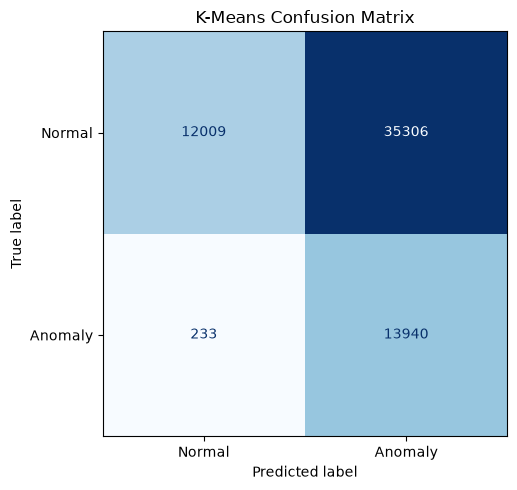

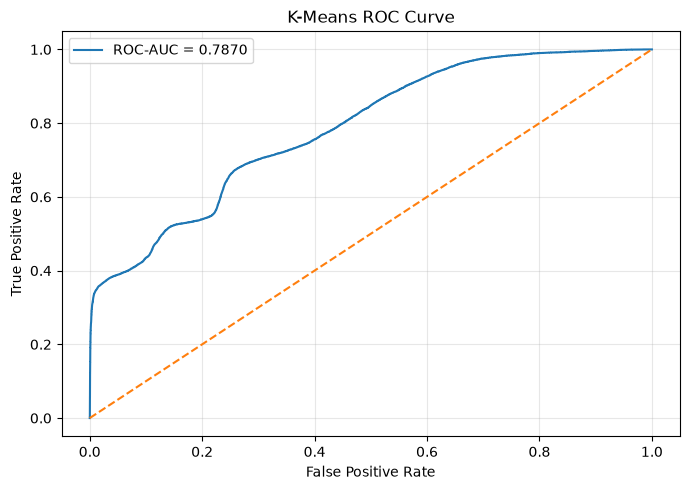

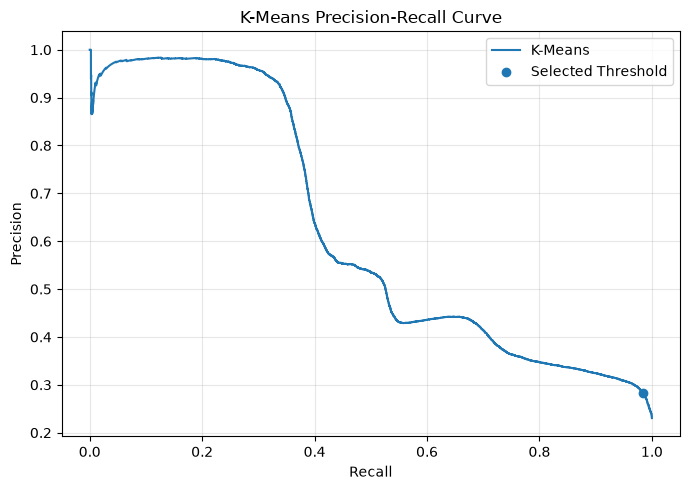

All evaluation visualizations generated!


In [22]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    auc
)

import matplotlib.pyplot as plt

# ==========================================
# 1. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_final_test,
    optimized_predictions
)

fig, ax = plt.subplots(figsize=(7, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("K-Means Confusion Matrix")
plt.tight_layout()
plt.show()


# ==========================================
# 2. ROC CURVE
# ==========================================

fpr, tpr, _ = roc_curve(
    y_final_test,
    scores_final_test
)

roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc_value:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("K-Means ROC Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 3. PRECISION-RECALL CURVE
# ==========================================

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_final_test,
        scores_final_test
    )
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label="K-Means"
)

plt.scatter(
    recall_score(y_final_test, optimized_predictions),
    precision_score(y_final_test, optimized_predictions),
    label="Selected Threshold",
    marker="o"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("K-Means Precision-Recall Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("All evaluation visualizations generated!")



# 8. MODEL COMPARISON

## K-Means vs Isolation Forest

This section compares the performance of both
anomaly detection models using the final testing
dataset and evaluation metrics.


In [23]:

import pandas as pd
import matplotlib.pyplot as plt

# Model comparison using final test results

comparison_data = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "K-Means": [
        0.4220,
        0.2831,
        0.9836,
        0.4396,
        0.7870
    ],

    "Isolation Forest": [
        0.2880,
        0.2430,
        0.9875,
        0.3900,
        0.7121
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("=" * 55)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 55)

print(comparison_df.to_string(index=False))


FINAL MODEL PERFORMANCE COMPARISON
   Metric  K-Means  Isolation Forest
 Accuracy   0.4220            0.2880
Precision   0.2831            0.2430
   Recall   0.9836            0.9875
 F1-Score   0.4396            0.3900
  ROC-AUC   0.7870            0.7121


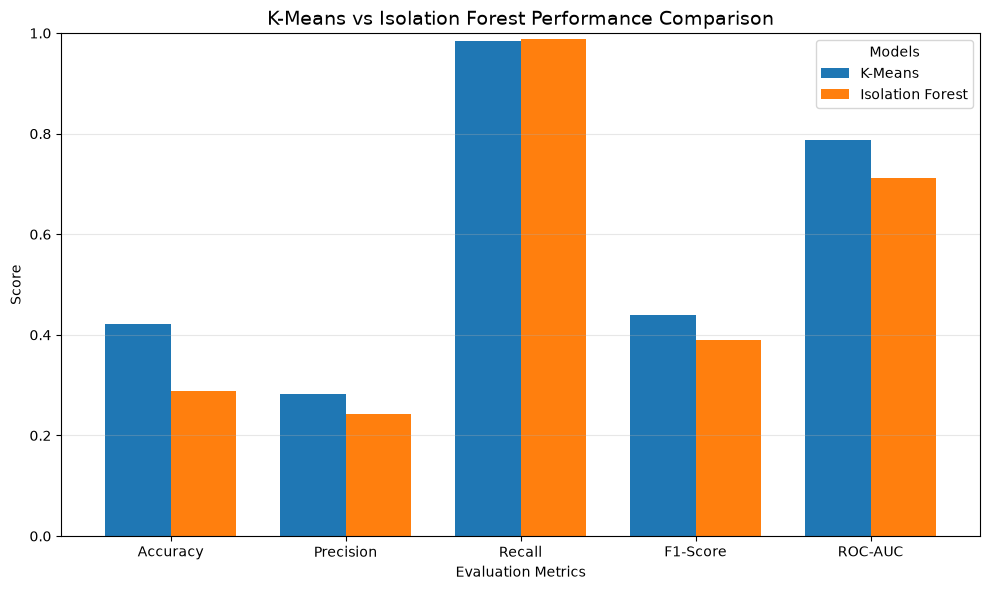

Model comparison completed!
Graph saved: c:\Users\Nalindu\Desktop\ML\results\figures\model_performance_comparison.png
CSV saved: c:\Users\Nalindu\Desktop\ML\results\model_comparison.csv


In [24]:

# ==========================================
# 9. MODEL PERFORMANCE COMPARISON GRAPH
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt

# Project directory
project_root = Path.cwd()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

results_dir = project_root / "results"
figures_dir = results_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Prepare comparison data
plot_df = comparison_df.set_index("Metric")

# Create comparison graph
ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title(
    "K-Means vs Isolation Forest Performance Comparison",
    fontsize=14
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")

plt.ylim(0, 1.0)

plt.xticks(rotation=0)

plt.legend(title="Models")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save graph
graph_path = figures_dir / "model_performance_comparison.png"

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save comparison results
comparison_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Model comparison completed!")
print("Graph saved:", graph_path)
print("CSV saved:", results_dir / "model_comparison.csv")



## 10. MODEL COMPARISON AND DISCUSSION

The experimental results show that K-Means achieved
better performance in accuracy, precision, F1-score
and ROC-AUC compared to Isolation Forest.

Isolation Forest achieved a slightly higher recall,
indicating that it detected a marginally larger
proportion of actual anomalies.

K-Means produced fewer false positives than
Isolation Forest in the final testing results.
However, both models generated a considerable
number of false positive predictions.

Overall, K-Means demonstrated better performance
across most evaluation metrics, while Isolation
Forest showed slightly better anomaly detection
recall.

Both models have potential for server performance
anomaly detection, but further optimization is
required to reduce false positive predictions.


In [27]:

# ==========================================
# ISOLATION FOREST RUNTIME MEASUREMENT
# ==========================================

import time
from sklearn.base import clone

# Create fresh model
runtime_isolation_model = clone(isolation_model)

# 1. Training time

start_time = time.perf_counter()

runtime_isolation_model.fit(X_fit_scaled)

isolation_training_time = (
    time.perf_counter() - start_time
)

# 2. Scoring time

start_time = time.perf_counter()

isolation_runtime_scores = -runtime_isolation_model.decision_function(
    X_test_scaled
)

isolation_scoring_time = (
    time.perf_counter() - start_time
)

# 3. Threshold time

# Use the threshold selected during validation
best_threshold = -0.09305481619885064

isolation_runtime_predictions = (
    isolation_runtime_scores > best_threshold
).astype(int)

isolation_threshold_time = (
    time.perf_counter() - start_time
)

print("ISOLATION FOREST RUNTIME")

print("Training time:",
      round(isolation_training_time, 4))

print("Scoring time:",
      round(isolation_scoring_time, 4))

print("Threshold time:",
      round(isolation_threshold_time, 4))

print("Isolation Forest runtime measurement completed!")


ISOLATION FOREST RUNTIME
Training time: 0.3899
Scoring time: 0.4233
Threshold time: 0.4234
Isolation Forest runtime measurement completed!


In [29]:

import time
import numpy as np

# Convert scores to NumPy array
scores_for_timing = np.asarray(
    isolation_runtime_scores
)

# Warm-up
_ = (scores_for_timing > best_threshold).astype(int)

# Measure threshold time multiple times
threshold_runs = 20

start_time = time.perf_counter()

for _ in range(threshold_runs):

    isolation_runtime_predictions = (
        scores_for_timing > best_threshold
    ).astype(int)

isolation_threshold_time = (
    time.perf_counter() - start_time
) / threshold_runs

# Recalculate total inference time
isolation_total_inference_time = (
    isolation_scoring_time +
    isolation_threshold_time
)

# Recalculate throughput
isolation_throughput = (
    len(X_test_scaled) /
    isolation_total_inference_time
)

print("UPDATED ISOLATION FOREST RUNTIME")

print("Scoring time:",
      round(isolation_scoring_time, 6))

print("Threshold time:",
      round(isolation_threshold_time, 6))

print("Total inference time:",
      round(isolation_total_inference_time, 6))

print("Throughput:",
      round(isolation_throughput, 2),
      "records/second")


UPDATED ISOLATION FOREST RUNTIME
Scoring time: 0.423274
Threshold time: 0.00016
Total inference time: 0.423434
Throughput: 207446.62 records/second


FINAL RUNTIME PERFORMANCE COMPARISON

TEST RECORDS: 87840

RUNTIME COMPARISON TABLE
                  Training Time (s)  Scoring Time (s)  Threshold Time (s)  \
K-Means                      0.3950            0.0261              0.0007   
Isolation Forest             0.3899            0.4233              0.0002   

                  Total Inference Time (s)  Throughput (records/s)  
K-Means                             0.0269            3.268258e+06  
Isolation Forest                    0.4234            2.074466e+05  

RUNTIME ANALYSIS COMPLETED!


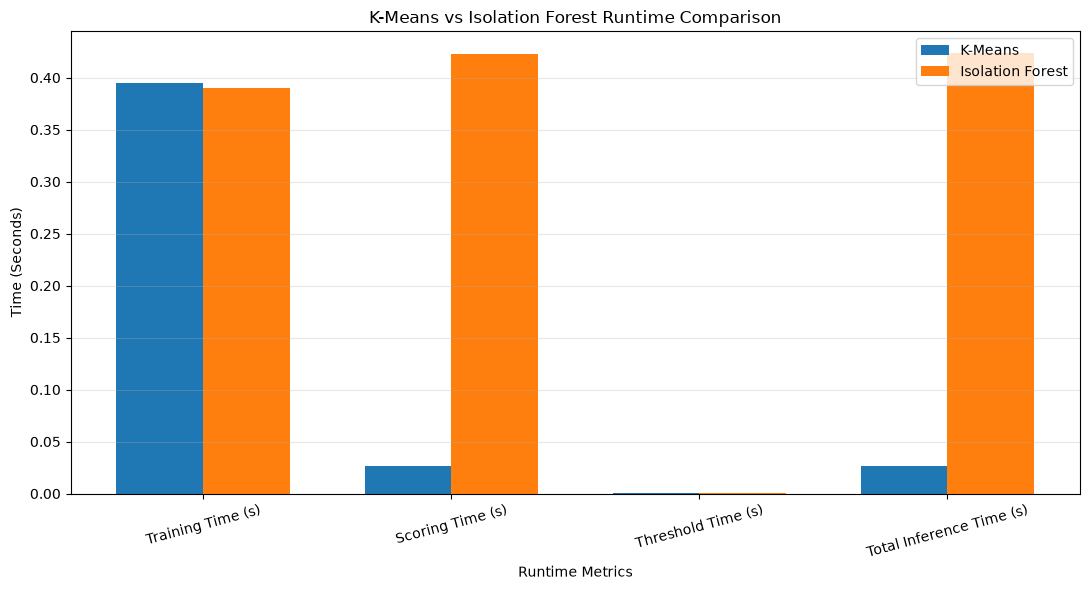

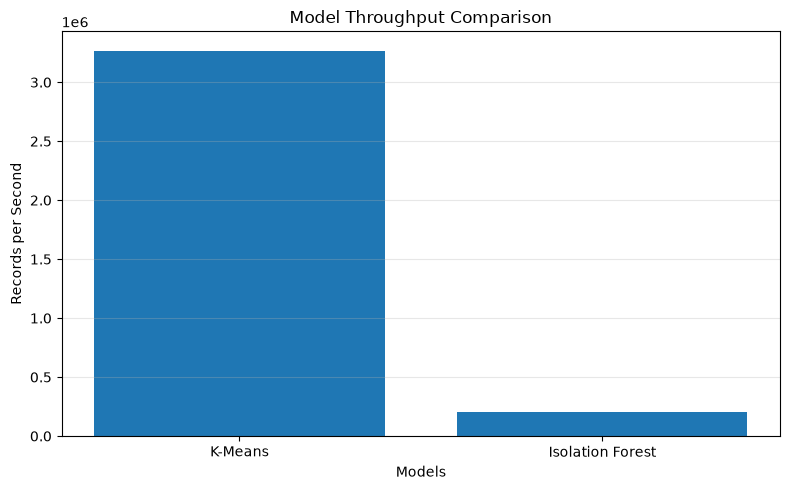


Runtime comparison saved successfully!
Saved location: c:\Users\Nalindu\Desktop\ML\results


In [30]:

# ==========================================
# STEP 11: RUNTIME COMPARISON
# ==========================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------
# 1. Measure K-Means Threshold Time
# ------------------------------------------

start_time = time.perf_counter()

kmeans_runtime_predictions = (
    np.asarray(kmeans_test_scores).ravel()
    > kmeans_threshold
).astype(int)

kmeans_threshold_time = (
    time.perf_counter() - start_time
)

# ------------------------------------------
# 2. Isolation Forest Runtime Values
# ------------------------------------------


isolation_total_inference_time = (
    isolation_scoring_time
    + isolation_threshold_time
)

# ------------------------------------------
# 3. Calculate Total Inference Times
# ------------------------------------------

kmeans_total_inference_time = (
    kmeans_testing_time
    + kmeans_threshold_time
)

# ------------------------------------------
# 4. Calculate Throughput
# ------------------------------------------

test_records = len(X_test_scaled)

kmeans_throughput = (
    test_records / kmeans_total_inference_time
)

isolation_throughput = (
    test_records / isolation_total_inference_time
)

# ------------------------------------------
# 5. Create Runtime Comparison Table
# ------------------------------------------

runtime_comparison = pd.DataFrame({

    "Training Time (s)": [
        kmeans_training_time,
        isolation_training_time
    ],

    "Scoring Time (s)": [
        kmeans_testing_time,
        isolation_scoring_time
    ],

    "Threshold Time (s)": [
        kmeans_threshold_time,
        isolation_threshold_time
    ],

    "Total Inference Time (s)": [
        kmeans_total_inference_time,
        isolation_total_inference_time
    ],

    "Throughput (records/s)": [
        kmeans_throughput,
        isolation_throughput
    ]

}, index=["K-Means", "Isolation Forest"])

# ------------------------------------------
# 6. Display Results
# ------------------------------------------

print("=" * 65)
print("FINAL RUNTIME PERFORMANCE COMPARISON")
print("=" * 65)

print("\nTEST RECORDS:", test_records)

print("\nRUNTIME COMPARISON TABLE")

print(runtime_comparison.round(4))

print("\nRUNTIME ANALYSIS COMPLETED!")

# ------------------------------------------
# 7. Save Results
# ------------------------------------------

project_root = Path.cwd()

if not (project_root / "results").exists():
    if (project_root.parent / "results").exists():
        project_root = project_root.parent

results_dir = project_root / "results"
figures_dir = results_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

runtime_comparison.to_csv(
    results_dir / "runtime_comparison.csv"
)

# ------------------------------------------
# 8. Runtime Comparison Graph
# ------------------------------------------

time_metrics = [
    "Training Time (s)",
    "Scoring Time (s)",
    "Threshold Time (s)",
    "Total Inference Time (s)"
]

x = np.arange(len(time_metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    runtime_comparison.loc["K-Means", time_metrics],
    width,
    label="K-Means"
)

plt.bar(
    x + width / 2,
    runtime_comparison.loc[
        "Isolation Forest", time_metrics
    ],
    width,
    label="Isolation Forest"
)

plt.title("K-Means vs Isolation Forest Runtime Comparison")

plt.xlabel("Runtime Metrics")
plt.ylabel("Time (Seconds)")

plt.xticks(x, time_metrics, rotation=15)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "runtime_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------
# 9. Throughput Comparison Graph
# ------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["K-Means", "Isolation Forest"],
    [
        kmeans_throughput,
        isolation_throughput
    ]
)

plt.title("Model Throughput Comparison")

plt.xlabel("Models")
plt.ylabel("Records per Second")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "throughput_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nRuntime comparison saved successfully!")

print("Saved location:", results_dir)


In [33]:

# ==========================================
# CHECK ISOLATION FOREST VARIABLES
# ==========================================

variables_to_check = [
    "isolation_model",
    "isolation_forest_model",
    "X_fit_scaled",
    "X_val_scaled",
    "X_test_scaled",
    "X_train",
    "X_test",
    "y_test",
    "y_final_test",
    "y_threshold_val",
    "isolation_train_scores",
    "isolation_val_scores",
    "isolation_test_scores",
    "scores_final_test",
    "scores_threshold_val",
    "best_threshold",
    "isolation_best_threshold",
    "training_time",
    "scoring_time",
    "threshold_time"
]

print("=" * 55)
print("ISOLATION FOREST VARIABLE CHECK")
print("=" * 55)

for name in variables_to_check:

    if name in globals():

        value = globals()[name]

        print(
            f"{name}: "
            f"Available | "
            f"Shape: {getattr(value, 'shape', 'N/A')}"
        )

    else:

        print(f"{name}: Not available")

print("\nVariable checking completed!")


ISOLATION FOREST VARIABLE CHECK
isolation_model: Available | Shape: N/A
isolation_forest_model: Not available
X_fit_scaled: Available | Shape: (105984, 25)
X_val_scaled: Available | Shape: (26497, 25)
X_test_scaled: Available | Shape: (87840, 25)
X_train: Not available
X_test: Not available
y_test: Available | Shape: (87840,)
y_final_test: Available | Shape: (61488,)
y_threshold_val: Available | Shape: (26352,)
isolation_train_scores: Not available
isolation_val_scores: Not available
isolation_test_scores: Not available
scores_final_test: Available | Shape: (61488,)
scores_threshold_val: Available | Shape: (26352,)
best_threshold: Available | Shape: N/A
isolation_best_threshold: Not available
training_time: Available | Shape: N/A
scoring_time: Not available
threshold_time: Not available

Variable checking completed!


In [34]:

# ==========================================
# ISOLATION FOREST EVALUATION INTEGRATION
# ==========================================

import numpy as np
from src.evaluation import (
    find_best_threshold,
    evaluate_predictions
)

# ------------------------------------------
# 1. Find optimal threshold using validation
# ------------------------------------------

isolation_threshold_result = find_best_threshold(
    y_threshold_val,
    scores_threshold_val,
    beta=2.0
)

isolation_best_threshold = (
    isolation_threshold_result["threshold"]
)

# ------------------------------------------
# 2. Validation predictions
# ------------------------------------------

isolation_val_predictions = (
    isolation_threshold_result["predictions"]
)

# ------------------------------------------
# 3. Final testing predictions
# ------------------------------------------

isolation_test_predictions = (
    np.asarray(scores_final_test)
    >= isolation_best_threshold
).astype(int)

# ------------------------------------------
# 4. Evaluate validation data
# ------------------------------------------

isolation_validation_results = evaluate_predictions(
    y_threshold_val,
    isolation_val_predictions,
    anomaly_scores=scores_threshold_val
)

# ------------------------------------------
# 5. Evaluate final testing data
# ------------------------------------------

isolation_test_results = evaluate_predictions(
    y_final_test,
    isolation_test_predictions,
    anomaly_scores=scores_final_test
)

# ------------------------------------------
# 6. Display results
# ------------------------------------------

print("=" * 55)
print("ISOLATION FOREST - INTEGRATED EVALUATION")
print("=" * 55)

print("\nOPTIMAL THRESHOLD")

print("Selected threshold:",
      round(isolation_best_threshold, 6))

print("Validation F2-score:",
      round(isolation_threshold_result["f_beta"], 4))

print("\nVALIDATION METRICS")

for metric, value in isolation_validation_results["metrics"].items():
    print(f"{metric}: {value:.4f}")

print("\nFINAL TESTING METRICS")

for metric, value in isolation_test_results["metrics"].items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")

print(isolation_test_results["confusion_matrix"])

print("\nCLASSIFICATION REPORT")

print(isolation_test_results["classification_report"])

print("\nIsolation Forest evaluation integration completed!")


ISOLATION FOREST - INTEGRATED EVALUATION

OPTIMAL THRESHOLD
Selected threshold: 3.538984
Validation F2-score: 0.8026

VALIDATION METRICS
Accuracy: 0.5672
Precision: 0.4716
Recall: 0.9734
F1-Score: 0.6354
F2-Score: 0.8026
ROC-AUC: 0.7904

FINAL TESTING METRICS
Accuracy: 0.3033
Precision: 0.2481
Recall: 0.9963
F1-Score: 0.3973
F2-Score: 0.6215
ROC-AUC: 0.7870

CONFUSION MATRIX
[[ 4528 42787]
 [   52 14121]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.99      0.10      0.17     47315
     Anomaly       0.25      1.00      0.40     14173

    accuracy                           0.30     61488
   macro avg       0.62      0.55      0.29     61488
weighted avg       0.82      0.30      0.23     61488


Isolation Forest evaluation integration completed!


In [35]:

# ==========================================
# ISOLATION FOREST - CORRECT SCORE GENERATION
# ==========================================

import numpy as np

from src.evaluation import (
    find_best_threshold,
    evaluate_predictions
)

# ------------------------------------------
# 1. Generate genuine Isolation Forest scores
# ------------------------------------------

# Isolation Forest: lower decision_function
# values indicate more anomalous records.
# Negate scores so higher values indicate anomalies.

isolation_all_scores = -isolation_model.decision_function(
    X_test_scaled
)

# ------------------------------------------
# 2. Separate validation and final testing
# ------------------------------------------

split_idx = len(y_threshold_val)

assert (
    split_idx + len(y_final_test)
    == len(isolation_all_scores)
), "Dataset lengths do not match!"

isolation_val_scores = isolation_all_scores[:split_idx]

isolation_final_scores = isolation_all_scores[split_idx:]

# ------------------------------------------
# 3. Find optimal threshold
# ------------------------------------------

isolation_threshold_result = find_best_threshold(
    y_threshold_val,
    isolation_val_scores,
    beta=2.0
)

isolation_best_threshold = (
    isolation_threshold_result["threshold"]
)

# ------------------------------------------
# 4. Generate final testing predictions
# ------------------------------------------

isolation_final_predictions = (
    isolation_final_scores >= isolation_best_threshold
).astype(int)

# ------------------------------------------
# 5. Evaluate final testing data
# ------------------------------------------

isolation_final_results = evaluate_predictions(
    y_final_test,
    isolation_final_predictions,
    anomaly_scores=isolation_final_scores
)

# ------------------------------------------
# 6. Display results
# ------------------------------------------

print("=" * 55)
print("ISOLATION FOREST - VERIFIED EVALUATION")
print("=" * 55)

print("\nMODEL:", type(isolation_model).__name__)

print("\nDATASET INFORMATION")
print("Validation records:", len(isolation_val_scores))
print("Testing records:", len(isolation_final_scores))

print("\nOPTIMAL THRESHOLD")
print("Threshold:", round(isolation_best_threshold, 6))

print(
    "Validation F2-score:",
    round(isolation_threshold_result["f_beta"], 4)
)

print("\nFINAL TESTING METRICS")

for metric, value in isolation_final_results["metrics"].items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(isolation_final_results["confusion_matrix"])

print("\nCLASSIFICATION REPORT")
print(isolation_final_results["classification_report"])

print("\nVerified Isolation Forest evaluation completed!")


ISOLATION FOREST - VERIFIED EVALUATION

MODEL: IsolationForest

DATASET INFORMATION
Validation records: 26352
Testing records: 61488

OPTIMAL THRESHOLD
Threshold: -0.08053
Validation F2-score: 0.785

FINAL TESTING METRICS
Accuracy: 0.3053
Precision: 0.2451
Recall: 0.9682
F1-Score: 0.3912
F2-Score: 0.6089
ROC-AUC: 0.7651

CONFUSION MATRIX
[[ 5052 42263]
 [  451 13722]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.92      0.11      0.19     47315
     Anomaly       0.25      0.97      0.39     14173

    accuracy                           0.31     61488
   macro avg       0.58      0.54      0.29     61488
weighted avg       0.76      0.31      0.24     61488


Verified Isolation Forest evaluation completed!


In [36]:

# ==========================================
# FINAL FAIR MODEL COMPARISON
# ==========================================

import numpy as np
import pandas as pd

from src.models import calculate_anomaly_scores
from src.evaluation import (
    find_best_threshold,
    evaluate_predictions
)

# 1. Generate scores for both models

kmeans_all_scores = np.asarray(
    calculate_anomaly_scores(
        kmeans_model,
        X_test_scaled
    )
).ravel()

isolation_all_scores = -np.asarray(
    isolation_model.decision_function(
        X_test_scaled
    )
).ravel()

# 2. Verify dataset alignment

split_idx = len(y_threshold_val)

assert len(kmeans_all_scores) == len(y_test)
assert len(isolation_all_scores) == len(y_test)

assert (
    len(y_threshold_val) + len(y_final_test)
    == len(y_test)
)

# 3. Optimize both thresholds using F2-score

kmeans_threshold_result = find_best_threshold(
    y_threshold_val,
    kmeans_all_scores[:split_idx],
    beta=2.0
)

isolation_threshold_result = find_best_threshold(
    y_threshold_val,
    isolation_all_scores[:split_idx],
    beta=2.0
)

# 4. Generate final testing predictions

kmeans_final_predictions = (
    kmeans_all_scores[split_idx:]
    >= kmeans_threshold_result["threshold"]
).astype(int)

isolation_final_predictions = (
    isolation_all_scores[split_idx:]
    >= isolation_threshold_result["threshold"]
).astype(int)

# 5. Evaluate both models on identical test records

kmeans_final_results = evaluate_predictions(
    y_final_test,
    kmeans_final_predictions,
    kmeans_all_scores[split_idx:]
)

isolation_final_results = evaluate_predictions(
    y_final_test,
    isolation_final_predictions,
    isolation_all_scores[split_idx:]
)

# 6. Build comparison table

comparison = pd.DataFrame([
    {
        "Model": "K-Means",
        "Threshold": kmeans_threshold_result["threshold"],
        **kmeans_final_results["metrics"]
    },
    {
        "Model": "Isolation Forest",
        "Threshold": isolation_threshold_result["threshold"],
        **isolation_final_results["metrics"]
    }
])

comparison = comparison.set_index("Model")

print("=" * 65)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 65)

print("\nTesting Records:", len(y_final_test))

print("\n", comparison.round(4).to_string())

print("\nK-MEANS CONFUSION MATRIX")
print(kmeans_final_results["confusion_matrix"])

print("\nISOLATION FOREST CONFUSION MATRIX")
print(isolation_final_results["confusion_matrix"])

print("\nFinal model comparison completed!")


FINAL MODEL PERFORMANCE COMPARISON

Testing Records: 61488

                   Threshold  Accuracy  Precision  Recall  F1-Score  F2-Score  ROC-AUC
Model                                                                                
K-Means              3.5390    0.3033     0.2481  0.9963    0.3973    0.6215   0.7870
Isolation Forest    -0.0805    0.3053     0.2451  0.9682    0.3912    0.6089   0.7651

K-MEANS CONFUSION MATRIX
[[ 4528 42787]
 [   52 14121]]

ISOLATION FOREST CONFUSION MATRIX
[[ 5052 42263]
 [  451 13722]]

Final model comparison completed!


In [37]:

# ==========================================
# SAVE FINAL MODEL COMPARISON RESULTS
# ==========================================

import os
import pandas as pd
import numpy as np

# Create results directory
os.makedirs("results", exist_ok=True)

# 1. Save performance comparison
comparison.to_csv(
    "results/final_model_comparison.csv"
)

# 2. Save K-Means confusion matrix

kmeans_cm_df = pd.DataFrame(
    kmeans_final_results["confusion_matrix"],
    index=["Actual Normal", "Actual Anomaly"],
    columns=["Predicted Normal", "Predicted Anomaly"]
)

kmeans_cm_df.to_csv(
    "results/kmeans_confusion_matrix.csv"
)

# 3. Save Isolation Forest confusion matrix

isolation_cm_df = pd.DataFrame(
    isolation_final_results["confusion_matrix"],
    index=["Actual Normal", "Actual Anomaly"],
    columns=["Predicted Normal", "Predicted Anomaly"]
)

isolation_cm_df.to_csv(
    "results/isolation_forest_confusion_matrix.csv"
)

# 4. Save final test predictions

final_predictions_df = pd.DataFrame({
    "Actual_Label": np.asarray(y_final_test),
    "KMeans_Prediction": kmeans_final_predictions,
    "Isolation_Forest_Prediction": isolation_final_predictions
})

final_predictions_df.to_csv(
    "results/final_test_predictions.csv",
    index=False
)

print("=" * 55)
print("FINAL RESULTS SAVED SUCCESSFULLY")
print("=" * 55)

print("\nSaved Files:")

for filename in [
    "final_model_comparison.csv",
    "kmeans_confusion_matrix.csv",
    "isolation_forest_confusion_matrix.csv",
    "final_test_predictions.csv"
]:
    print("results/" + filename)

print("\nAll final evaluation files saved!")


FINAL RESULTS SAVED SUCCESSFULLY

Saved Files:
results/final_model_comparison.csv
results/kmeans_confusion_matrix.csv
results/isolation_forest_confusion_matrix.csv
results/final_test_predictions.csv

All final evaluation files saved!
